# Självstudieövningar – Vecka 5

De här övningarna är till för att du ska repetera och befästa det vi har gått igenom under veckan samt introducera några nya begrepp på ett tryggt sätt.

Det innebär att vissa av uppgifterna kan du behöva söka efter information själv hur du löser. Här kan du använda Google eller AI om du vill men dokumentationerna är din bästa vän när du lär dig.
- Python: https://docs.python.org/3.13/
- Matplotlib: https://matplotlib.org/stable/
- Pandas: https://pandas.pydata.org/
- NumPy: https://numpy.org/

Läs först igenom vad som ska göras i respektive uppgift och fyll sedan i kodblocket nedanför, eller gör uppgiften i en separat fil.

**Detta lämnas inte in för rättning.** Arbeta i din egen takt, testa dig fram, använd dokumentationen när du kör fast och ta med eventuella frågor till nästa lektionstillfälle.

## (Kör först) Skapa veckans dataset

In [1]:
%load_ext autoreload 
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(123)

n = 800
cities = np.array(["Göteborg","Malmö","Stockholm","Uppsala"])
genders = np.array(["F","M"])
groups = np.array(["A","B"])  # för A/B-experiment

city = rng.choice(cities, size=n, p=[0.28, 0.22, 0.40, 0.10])
gender = rng.choice(genders, size=n)
age = rng.integers(18, 65, size=n)

# A/B-tilldelning (balanced med lite slump)
group = rng.choice(groups, size=n)

# Aktivitet (ungefär som "engagement score")
base = rng.normal(60, 12, size=n)

# Små effekter från stad/kön
city_shift = {"Göteborg":2, "Malmö":-1, "Stockholm":1, "Uppsala":0}
gender_shift = {"F":1.5, "M":0}
score = base + np.vectorize(city_shift.get)(city) + np.vectorize(gender_shift.get)(gender)

# Effekt av grupp: B ger +2 i snitt
score = score + np.where(group=="B", 2.0, 0.0)

# Begränsa och runda
score = np.clip(score, 10, 100)

# Binärt utfall (t.ex. "köp"): sannolikhet ökar med score
p_buy = 1/(1 + np.exp(-(score-55)/10))
purchase = rng.binomial(1, p_buy)

# Intäkter för köp (lognormal-ish), 0 om inget köp
revenue = np.where(purchase==1, rng.lognormal(mean=3.2, sigma=0.5, size=n), 0.0)

# Lägg in lite saknade värden
df = pd.DataFrame({
    "city": city,
    "gender": gender,
    "age": age,
    "group": group,
    "score": np.round(score,1),
    "purchase": purchase,
    "revenue": np.round(revenue,2)
})
mask = rng.random(size=df.shape) < 0.01  # ~1% NaN
for (r,c),m in np.ndenumerate(mask):
    if m:
        df.iat[r,c] = np.nan

df.to_csv("files/customer_activity.csv", index=False)
print("Skapade customer_activity.csv med", len(df), "rader.")

Skapade customer_activity.csv med 800 rader.


### Om datasetet (`customer_activity.csv`)

Det här är ett syntetiskt dataset från en fiktiv digital tjänst. Varje rad representerar en kundobservation.

| Kolumn | Typ | Beskrivning |
|---|---|---|
| `city` | kategori | Kundens stad |
| `gender` | kategori | Kön (F/M) |
| `age` | heltal | Ålder |
| `group` | kategori | Grupp A eller B |
| `score` | decimaltal | Aktivitet eller engagemang, 10–100 |
| `purchase` | 0/1 | Om kunden genomförde ett köp |
| `revenue` | decimaltal | Intäkt, 0 om inget köp genomfördes |

Grupp B har en liten positiv effekt på `score`. Sannolikheten för ett köp ökar med högre `score`. Datasetet innehåller även några saknade värden för att ge möjlighet att öva datarengöring.

Eftersom datasetet är syntetiskt ska det användas för att träna analysmetoder. Resultaten beskriver inte verkliga kunder.

### Snabb kontroll

- Läs in `customer_activity.csv` i en DataFrame som heter `df`.
- Visa de första raderna.
- Kontrollera datatyperna.
- Räkna antalet saknade värden per kolumn.
- Skriv en kort kommentar om något du reagerar på, exempelvis att `revenue` ofta är 0 eftersom alla kunder inte har genomfört ett köp.

In [2]:
df = pd.read_csv('files/customer_activity.csv')
print(df.info(),"\n")
print(df.describe(),"\n")
print(f'missing values: \n{df.isna().sum()}')
# median och medelvärde överensstämmer ofta ganska bra

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   city      795 non-null    str    
 1   gender    788 non-null    str    
 2   age       791 non-null    float64
 3   group     792 non-null    str    
 4   score     792 non-null    float64
 5   purchase  793 non-null    float64
 6   revenue   789 non-null    float64
dtypes: float64(4), str(3)
memory usage: 43.9 KB
None 

              age       score    purchase     revenue
count  791.000000  792.000000  793.000000  789.000000
mean    40.906448   61.830682    0.644388   17.768492
std     13.230148   11.841072    0.479000   17.300148
min     18.000000   23.500000    0.000000    0.000000
25%     29.000000   53.775000    0.000000    0.000000
50%     41.000000   61.500000    1.000000   16.780000
75%     52.000000   69.925000    1.000000   29.040000
max     64.000000   97.800000    1.000000   93.550000 

missing valu

## Block A – Fördjupning i Matplotlib

### Uppgift 1 – Tema, grid och etiketter
Rita en valfri figur över `score` (t.ex. histogram eller KDE) och förbättra läsbarheten:
- lägg till titel, axelrubriker, rutnät,
- justera tick-etiketter om det behövs,
- (tips: `plt.style.use(...)`, `plt.grid(True)`, `plt.xticks(rotation=...)`).

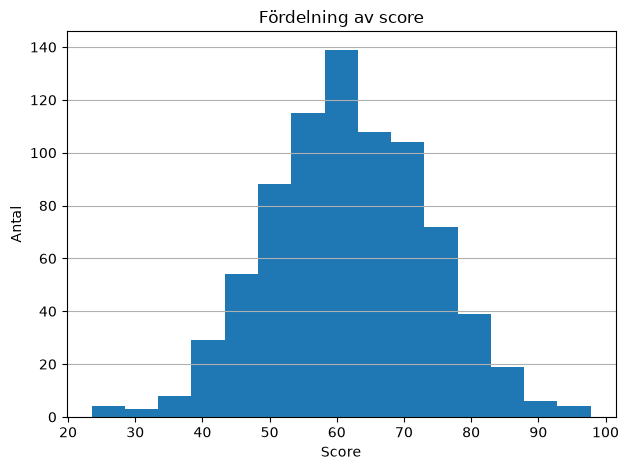

In [3]:
fig, ax = plt.subplots()
ax.hist(df['score'].dropna(), bins=15)
ax.set_title('Fördelning av score')
ax.set_xlabel('Score')
ax.set_ylabel('Antal')
ax.grid(True, axis="y")
plt.tight_layout()

### Uppgift 2 – Flera paneler (subplots)
Gör två subplots bredvid varandra:
- till vänster: histogram av `score`,
- till höger: stapeldiagram över frekvens per `city`.
Se till att layouter inte överlappar (tips: `plt.tight_layout()`).

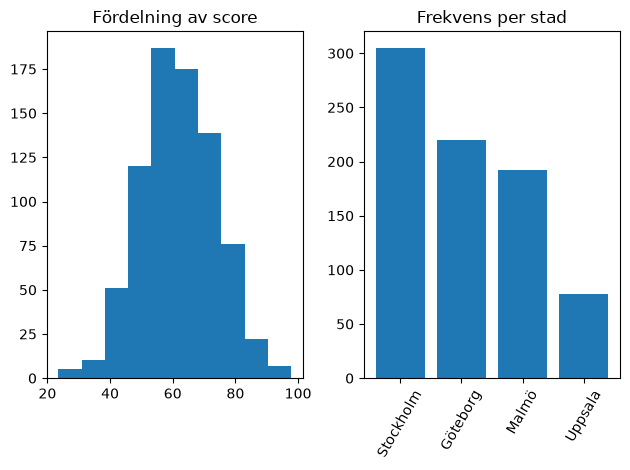

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.hist(df['score'])
ax1.set_title('Fördelning av score')

ax2.bar(df['city'].value_counts().index, df['city'].value_counts())
plt.xticks(rotation=60)
ax2.set_title('Frekvens per stad')
plt.tight_layout()



### Uppgift 3 – Färger och annoteringar
Rita en boxplot av `score` uppdelad på `group` och:
- färgsätt grupperna olika,
- lägg in en **horisontell referenslinje** vid `score = 60`,
- annotera grafen med en kort textpil som pekar på en intressant del.
*(tips: `ax.axhline(...)`, `ax.annotate(...)`)*

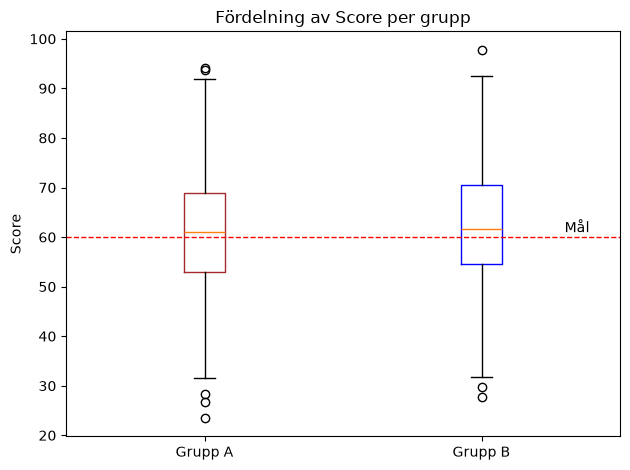

In [5]:
fig, ax = plt.subplots()
df = df.dropna()

ax.boxplot(
    df[df["group"].str.strip().str.upper() == "A"]["score"],
    positions=[1],
    boxprops=dict(color="brown")
    )

ax.boxplot(
    df[df["group"].str.strip().str.upper() == "B"]["score"],
    positions=[2],
    boxprops=dict(color="blue")
    )

ax.set_title('Fördelning av Score per grupp')
ax.set_xticklabels(['Grupp A', 'Grupp B'])
ax.set_ylabel('Score')

ax.axhline(y=60, color="red", linestyle="--", linewidth=1,  label="Mål (60)")
ax.annotate('Mål', xy=(2.3, 61))
plt.tight_layout()
plt.show()

### Uppgift 4 – Felsökning: filnamn, legend och etiketter

Koden ska jämföra fördelningen av `score` i grupp A och grupp B, men den innehåller flera problem. Kör koden, undersök felmeddelanden och rätta den.

```python
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("weekX_data.csv")

group_a = df.loc[df["group"] == "A", "score"].dropna()
group_b = df.loc[df["group"] == "B", "score"].dropna()

fig, ax = plt.subplots()

ax.hist(group_a, bins=20, alpha=0.6, label="Grupp A")
ax.hist(group_b, bins=20, alpha=0.6)

ax.legend()
plt.show()
```

När koden är rättad ska den:

- läsa in rätt fil,
- visa båda grupperna i legenden,
- ha en beskrivande titel,
- ha tydliga axelrubriker,
- använda färger eller transparens så att grupperna går att jämföra.

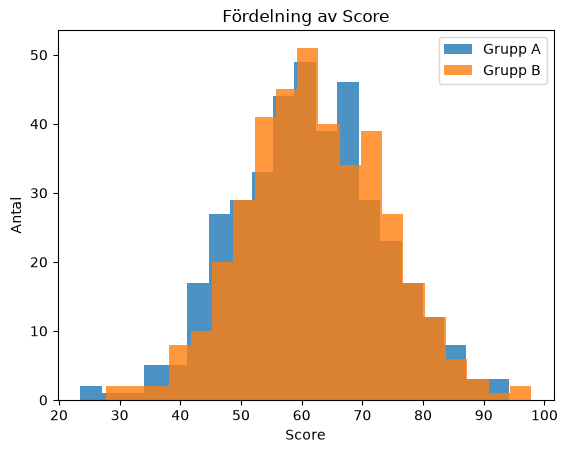

In [6]:
df = pd.read_csv("files/customer_activity.csv")

group_a = df.loc[df["group"] == "A", "score"].dropna()
group_b = df.loc[df["group"] == "B", "score"].dropna()

fig, ax = plt.subplots()

ax.hist(group_a, bins=20, alpha=0.8, label="Grupp A")
ax.hist(group_b, bins=20, alpha=0.8, label='Grupp B')

ax.set_title('Fördelning av Score')
ax.set_xlabel('Score')
ax.set_ylabel('Antal')

ax.legend()
plt.show()

### Uppgift 5 – Välj rätt figur
Du vill jämföra distributionen av `revenue` mellan `group` **för de som köpt** (`purchase==1`). 
- Välj en **lämplig** figurtyp (motivera kort i en kommentar).
- Rita grafen och gör den läsbar (titel, axlar, grid).

27.59
27.52


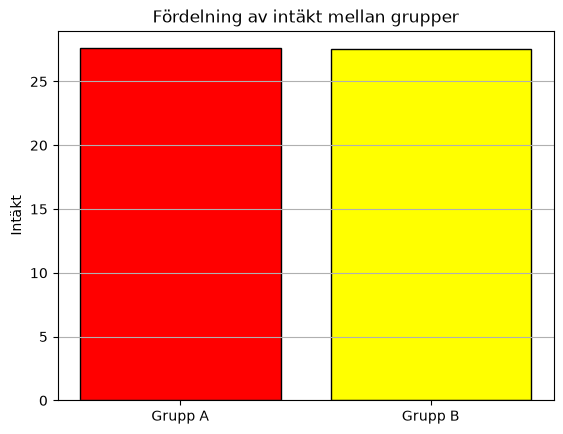

In [7]:
df_purch = df[df['purchase'] == 1]

fig, ax = plt.subplots()
ax.bar(
    ['Grupp A', 'Grupp B'],
    [df_purch[df_purch['group'].str.strip().str.upper() == 'A']['revenue'].mean(),
     df_purch[df_purch['group'].str.strip().str.upper() == 'B']['revenue'].mean()],
     edgecolor='black',
     color=['red', 'yellow'])

ax.grid(True, axis= 'y')

ax.set_title('Fördelning av intäkt mellan grupper')
ax.set_ylabel('Intäkt')
print(df_purch[df_purch['group'].str.strip().str.upper() == 'A']['revenue'].mean().round(2))
print(df_purch[df_purch['group'].str.strip().str.upper() == 'B']['revenue'].mean().round(2))

## Block B – EDA med Python

### Uppgift 6 – Grundprofil
- Räkna frekvens per `city` och `gender`.
- Räkna andel som köpt (`purchase`-medel fungerar här) per `city`.
- Skapa en tabell med medel/median för `score` och `revenue` per `group` och `gender`.
*(tips: `groupby(...).agg({...})`)*

In [8]:
df_clean = df.dropna()


df_bycity_gender = df_clean.groupby(['city', 'gender']).agg(antal = ('gender', 'count')).unstack(fill_value=0)
print('Könsfördelning per stad\n', df_bycity_gender, '\n')

df_purch2 = df_clean.groupby(['city']).agg(
    andel = ('purchase', 'mean'))
print('Andel som handlat\n', (df_purch2 * 100).round(1))


pivot = pd.pivot_table(
    df_clean,
    values=['score', 'revenue'],
    index='gender',
    columns='group',
    aggfunc=["mean", 'median']
).round(2)

print(pivot)

Könsfördelning per stad
           antal     
gender        F    M
city                
Göteborg     96  113
Malmö        73  103
Stockholm   137  143
Uppsala      34   43 

Andel som handlat
            andel
city            
Göteborg    61.2
Malmö       61.9
Stockholm   66.4
Uppsala     72.7
          mean                       median                   
       revenue         score        revenue        score      
group        A      B      A      B       A      B     A     B
gender                                                        
F        16.67  17.78  61.84  61.34   15.89  16.01  61.0  60.8
M        18.79  17.43  60.69  62.79   17.48  16.03  60.9  62.0


### Uppgift 7 – Samband mellan variabler
- Skapa ett **spridningsdiagram** med `score` (x) och `revenue` (y) **endast för köp**.
- Lägg gärna på en enkel trendlinje eller glidande medelvärde (valfritt).
- Kommentera om sambandet ser linjärt ut eller ej.

C:\Users\fdasfda\AppData\Local\Temp\ipykernel_7808\3482059730.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


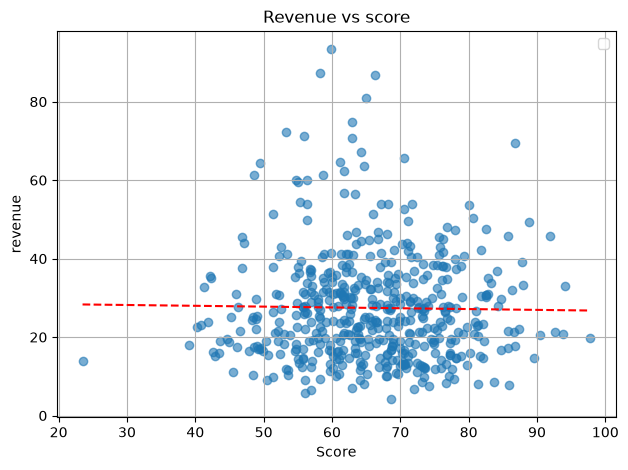

In [9]:
fig, ax = plt.subplots()
df_purch = df_purch.dropna(subset=['score', 'revenue'])

ax.scatter(df_purch['score'], df_purch['revenue'], alpha=0.6)
ax.set_title("Revenue vs score")
ax.set_xlabel("Score")
ax.set_ylabel("revenue")
ax.grid(True)

#regression line
k, m = np.polyfit(df_purch['score'], df_purch['revenue'], 1)
x = np.linspace(df_clean['score'].min(), df_clean['score'].max(), 100)
y = k * x + m
ax.plot(x, y, color='red', linestyle='--')

ax.legend()
plt.tight_layout()
plt.show()

# sambandet är inte linjärt, det ser slumpmässigt ut

### Uppgift 8 – Rensa saknade värden
- Räkna saknade värden per kolumn.
- Fyll saknade i `age` med median; i `score` med medelvärde.
- Verifiera att saknade minskat.
*(tips: `fillna(...)`)*

In [ ]:
print(f"before: \n{df.isna().sum()}")
df_cleaned2 = df.copy()
df_cleaned2['age'] = df_cleaned2['age'].fillna(df_cleaned2['age'].median())
df_cleaned2['score'] = df_cleaned2['score'].fillna(df_cleaned2['score'].median)


print(f"after: \n{df_cleaned2.isna().sum()}")

before: 
city         5
gender      12
age          9
group        8
score        8
purchase     7
revenue     11
dtype: int64
after: 
city         5
gender      12
age          0
group        8
score        0
purchase     7
revenue     11
dtype: int64


### Uppgift 9 – Mini-EDA

Genomför en mindre utforskande dataanalys av `customer_activity.csv`.

#### 1. Formulera frågor

Välj minst tre frågor som du vill undersöka. Du kan exempelvis undersöka:

- Skiljer sig `score` mellan grupp A och grupp B?
- Verkar kunder med högre `score` köpa oftare?
- Skiljer sig köpfrekvensen mellan olika städer?
- Hur ser fördelningen av `revenue` ut bland kunder som har genomfört ett köp?
- Finns det något synligt samband mellan ålder och `score`?

Du får formulera egna frågor.

#### 2. Kontrollera och förbered data

- kontrollera datatyper och saknade värden,
- avgör vilka saknade värden som behöver hanteras,
- filtrera data när det behövs för analysen,
- dokumentera kort vilka beslut du fattar.

#### 3. Sammanfatta data

Använd lämpliga sammanfattningar, exempelvis:

- antal och andelar,
- medelvärde och median,
- gruppering med `groupby()`,
- frekvenstabeller.

#### 4. Visualisera

Skapa minst tre visualiseringar som hjälper dig att besvara frågorna.

Välj figurtyp utifrån vilken typ av fråga och vilka variabler du undersöker. Varje figur ska ha:

- en tydlig titel,
- relevanta axelrubriker,
- läsbar skala och layout,
- en legend när den behövs.

Spara minst en figur som en bildfil.

#### 5. Sammanfatta dina observationer

Skriv 3–5 korta observationer från analysen. Skilj mellan:

- vad som faktiskt syns i data,
- möjliga förklaringar som skulle behöva undersökas vidare.

Undvik att beskriva samband som orsakssamband om analysen inte ger stöd för det.

In [ ]:
# Se separat fil mini_EDA_for_week5